In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
from sklearn.feature_extraction.text import CountVectorizer
import gc

gc.collect()
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

In [2]:
train_df = pd.read_parquet('./Dataset/original/train.parquet')
val_df = pd.read_parquet('./Dataset/original/val.parquet')
test_df = pd.read_parquet('./Dataset/original/test.parquet')
dfs = {'Train': train_df, 'Validation': val_df, 'Test': test_df}

n = 0
for i in dfs:
    print(f"{i} Dataset Cardinality : {dfs[i].shape[0]}")
    n += dfs[i].shape[0]
print(f"Total number of entries : {n}")

Train Dataset Cardinality : 796800
Validation Dataset Cardinality : 99600
Test Dataset Cardinality : 99600
Total number of entries : 996000


In [3]:
integrity_stats = []

for name, df in dfs.items():
    total_rows = len(df)
    null_count = df['text'].isnull().sum()
    empty_str_count = (df['text'].str.strip() == '').sum()
    duplicates = df.duplicated(subset=['text']).sum()
    duplicate_percent = duplicates/total_rows
    
    integrity_stats.append({
        'Split': name,
        'Total Rows': total_rows,
        'Nulls/NaNs': null_count,
        'Empty Strings': empty_str_count,
        'Within-Split Duplicates': duplicates,
        'Within-Split Duplicate Percentage': f"{duplicate_percent:.3%}"
    })

integrity_df = pd.DataFrame(integrity_stats)
display(integrity_df)

total = sum([len(df) for df in dfs.values()])
print(f"Split Ratios -> Train: {len(train_df)/total:.1%}, Val: {len(val_df)/total:.1%}, Test: {len(test_df)/total:.1%}")

,Split,Total Rows,Nulls/NaNs,Empty Strings,Within-Split Duplicates,Within-Split Duplicate Percentage
0,Train,796800,0,0,21191,2.660%
1,Validation,99600,0,0,359,0.360%
2,Test,99600,0,0,359,0.360%


Split Ratios -> Train: 80.0%, Val: 10.0%, Test: 10.0%


In [4]:
train_texts = set(train_df['text'].dropna())
val_texts = set(val_df['text'].dropna())
test_texts = set(test_df['text'].dropna())

leakage_train_val = len(train_texts.intersection(val_texts))
leakage_train_test = len(train_texts.intersection(test_texts))
leakage_val_test = len(val_texts.intersection(test_texts))

print(f"Exact Matches Train <-> Val  : {leakage_train_val}")
print(f"Exact Matches Train <-> Test : {leakage_train_test}")
print(f"Exact Matches Val   <-> Test : {leakage_val_test}")

Exact Matches Train <-> Val  : 4920
Exact Matches Train <-> Test : 4920
Exact Matches Val   <-> Test : 99241


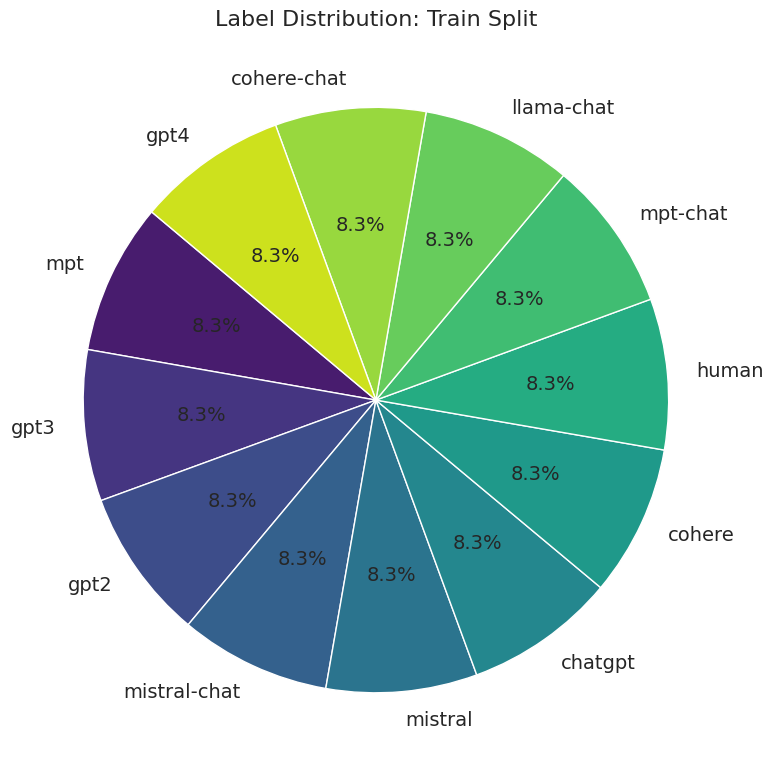

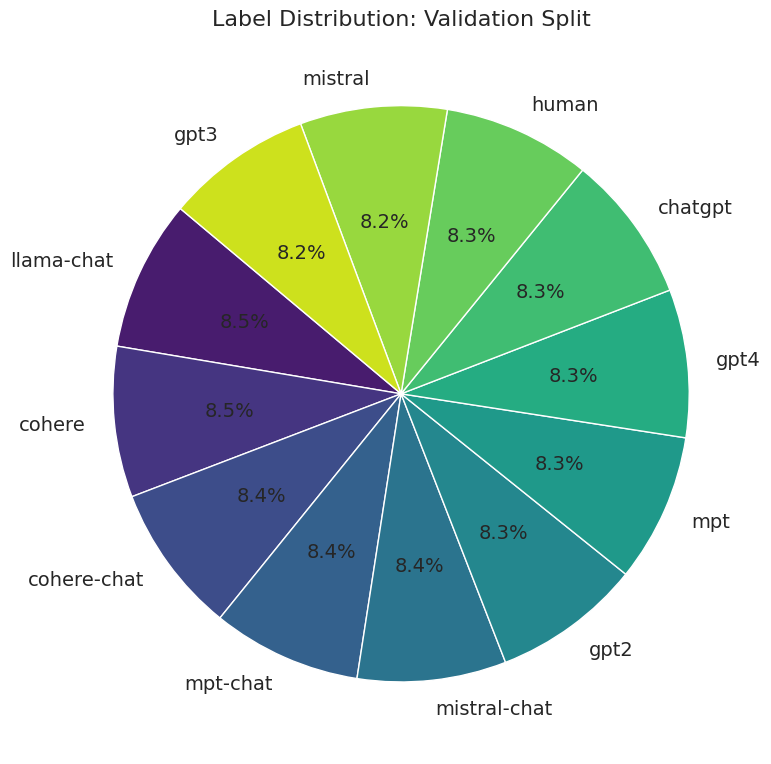

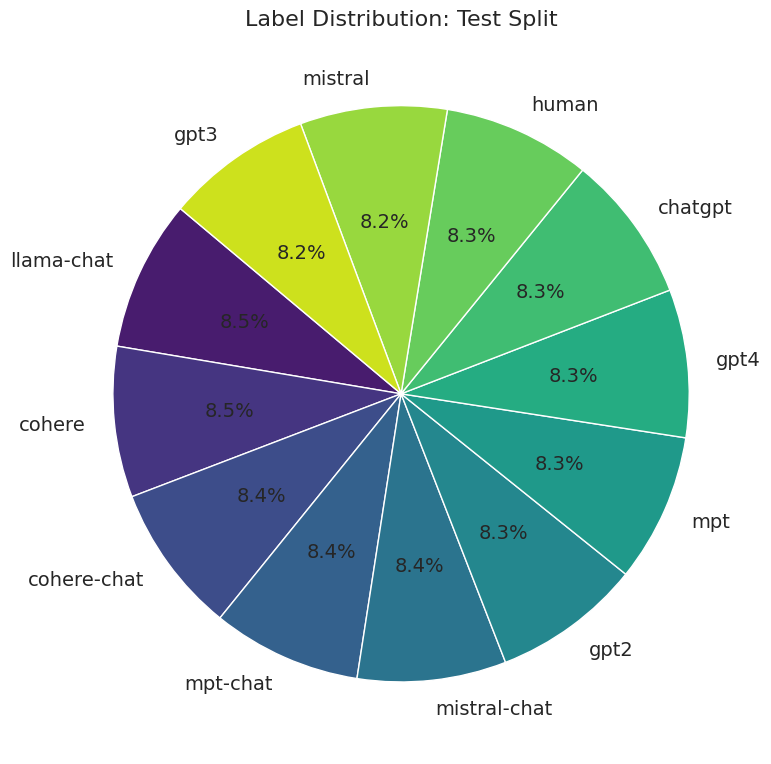

In [3]:
# Loop through the dictionary and create a separate pie chart for each split
for name, df in dfs.items():
    plt.figure(figsize=(8, 8)) # Square figures usually look best for pie charts
    
    # Calculate the frequency of each category
    counts = df['generated_by'].value_counts()
    
    # Extract the viridis color palette with the exact number of colors we need
    colors = sns.color_palette('viridis', len(counts))
    
    # Create the pie chart
    plt.pie(
        x=counts, 
        labels=counts.index, 
        autopct='%1.1f%%',       # Shows the percentage inside the pie (1 decimal place)
        startangle=140,          # Rotates the start of the pie for a better look
        colors=colors,
        wedgeprops={'edgecolor': 'white'}, # Adds a clean white border between slices
        textprops={'fontsize': 14}
    )
    
    plt.title(f'Label Distribution: {name} Split', fontsize=16)
    
    plt.tight_layout()
    plt.savefig(f'/home/ayush/Documents/AI_project/report/images/pie_{name.lower()}.png', dpi=300, bbox_inches='tight', transparent=False)
    plt.show()

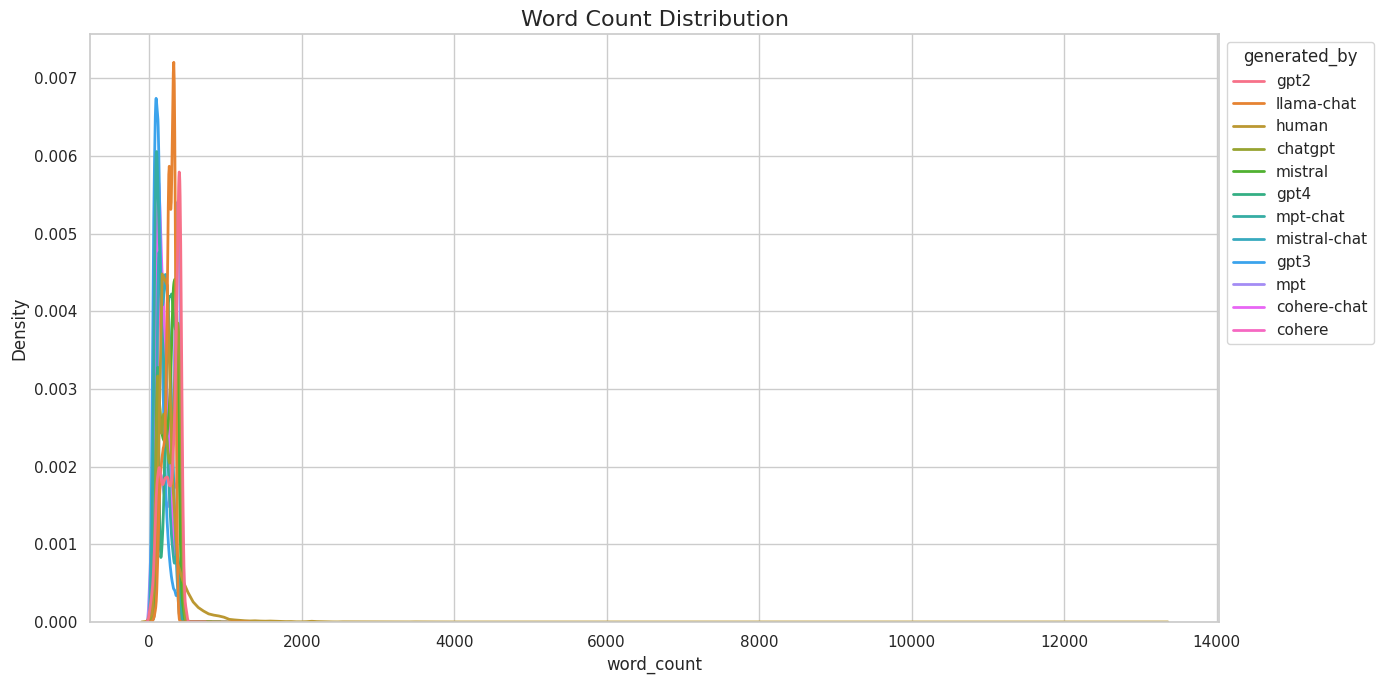

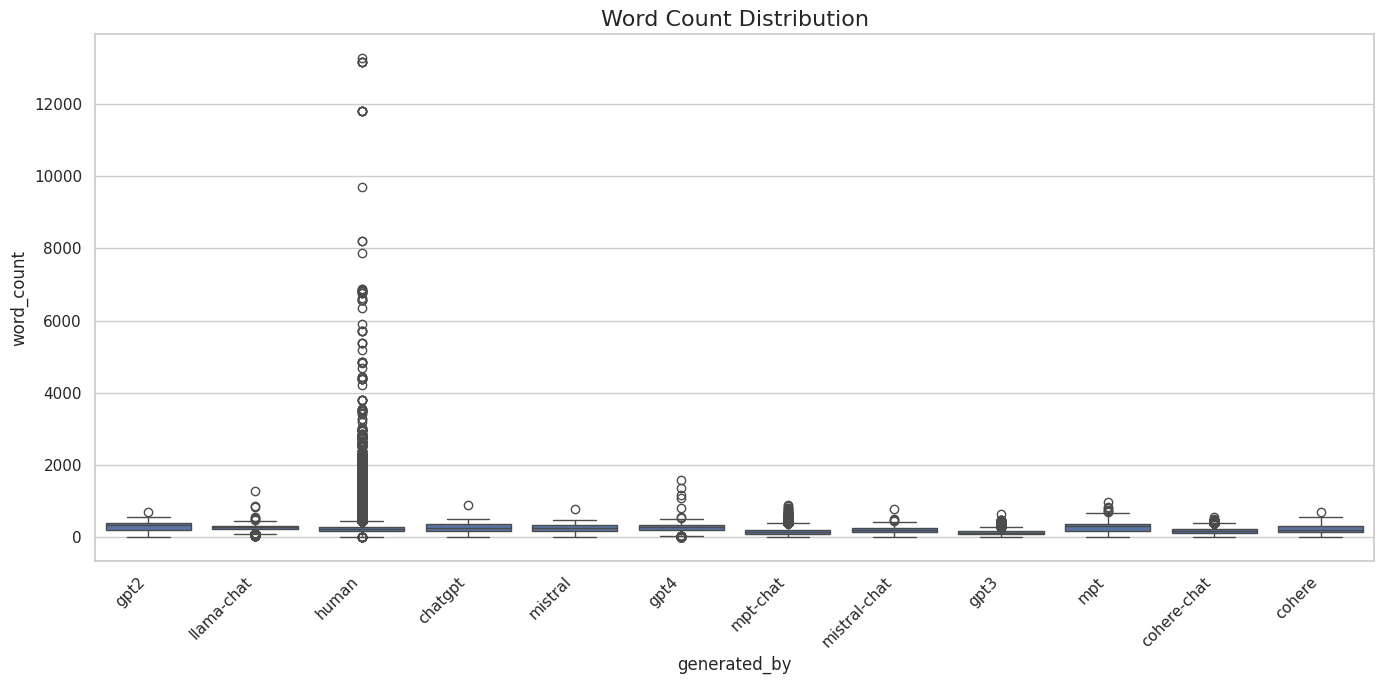

Word Count Percentiles:
75%      319.0
90%      382.0
95%      407.0
99%      463.0
max    13261.0
Name: word_count, dtype: float64


In [6]:
train_df['word_count'] = train_df['text'].apply(lambda x: len(str(x).split()))
train_df['char_count'] = train_df['text'].apply(lambda x: len(str(x)))

# --- Plot 1: Word Count Line Plot (KDE) ---
plt.figure(figsize=(14, 7))
# KDE plot draws a smooth line representing the distribution. 
# common_norm=False ensures smaller categories are still visible.
ax1 = sns.kdeplot(data=train_df, x='word_count', hue='generated_by', 
                  common_norm=False, linewidth=2)
plt.title(f'Word Count Distribution', fontsize=16)

sns.move_legend(ax1, "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

# --- Plot 2: Character Count Boxplot (Cleaned) ---
plt.figure(figsize=(14, 7))
# showfliers=False hides the massive outlier dots that squash the boxes flat
sns.boxplot(data=train_df, x='generated_by', y='word_count')
plt.title('Word Count Distribution', fontsize=16)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'./images/Word Count Distribution Boxplot.png', dpi=300, bbox_inches='tight', transparent=False)
plt.show()

# --- Percentile Stats ---
percentiles = [0.75, 0.90, 0.95, 0.99]
print("Word Count Percentiles:")
print(train_df['word_count'].describe(percentiles=percentiles)[['75%', '90%', '95%', '99%', 'max']])

In [7]:
cleaned_df = train_df.copy()

def truncate_text(text, max_words=512):
    words = str(text).split()
    if len(words) > max_words:
        return " ".join(words[:max_words])
    return str(text)

# Apply truncation
cleaned_df['text'] = cleaned_df['text'].apply(truncate_text)

# Recalculate the word and character counts on the truncated text
cleaned_df['word_count'] = cleaned_df['text'].apply(lambda x: len(str(x).split()))
cleaned_df['char_count'] = cleaned_df['text'].apply(lambda x: len(str(x)))

print(f"Max word count before: {train_df['word_count'].max()}")
print(f"Max word count after: {cleaned_df['word_count'].max()}")

Max word count before: 13261
Max word count after: 512


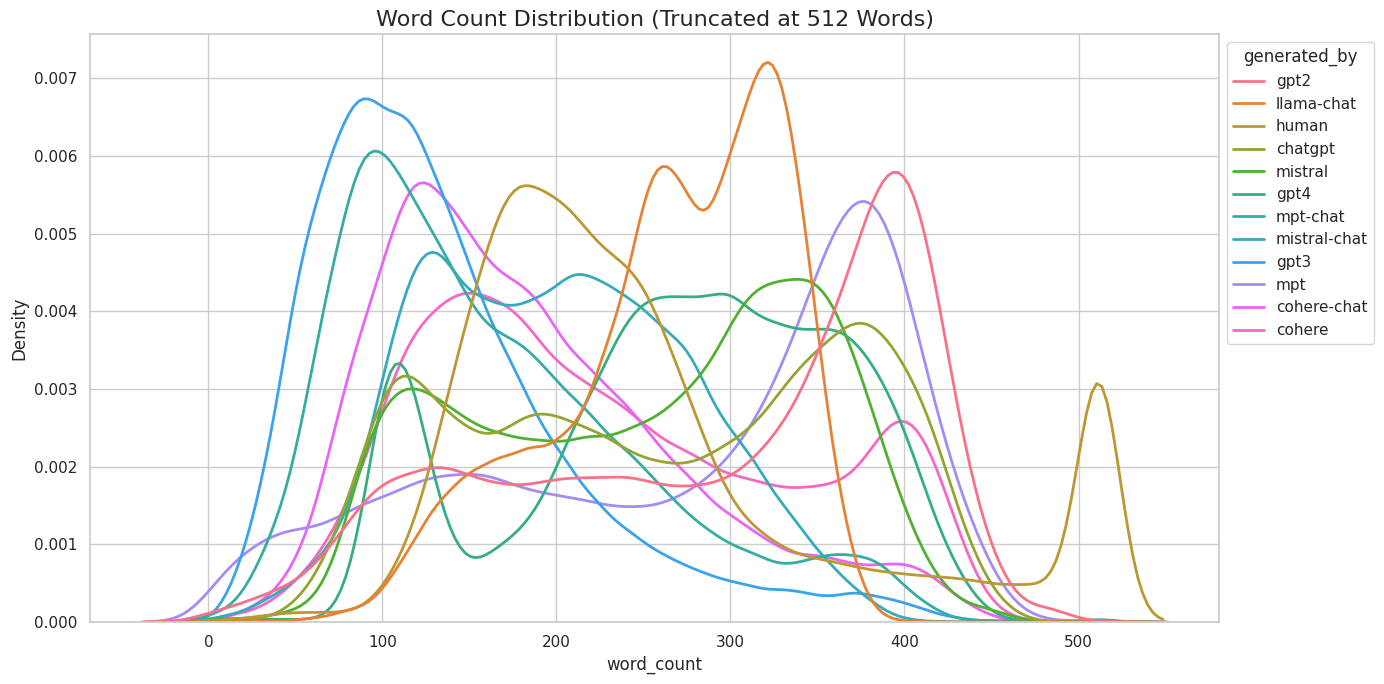

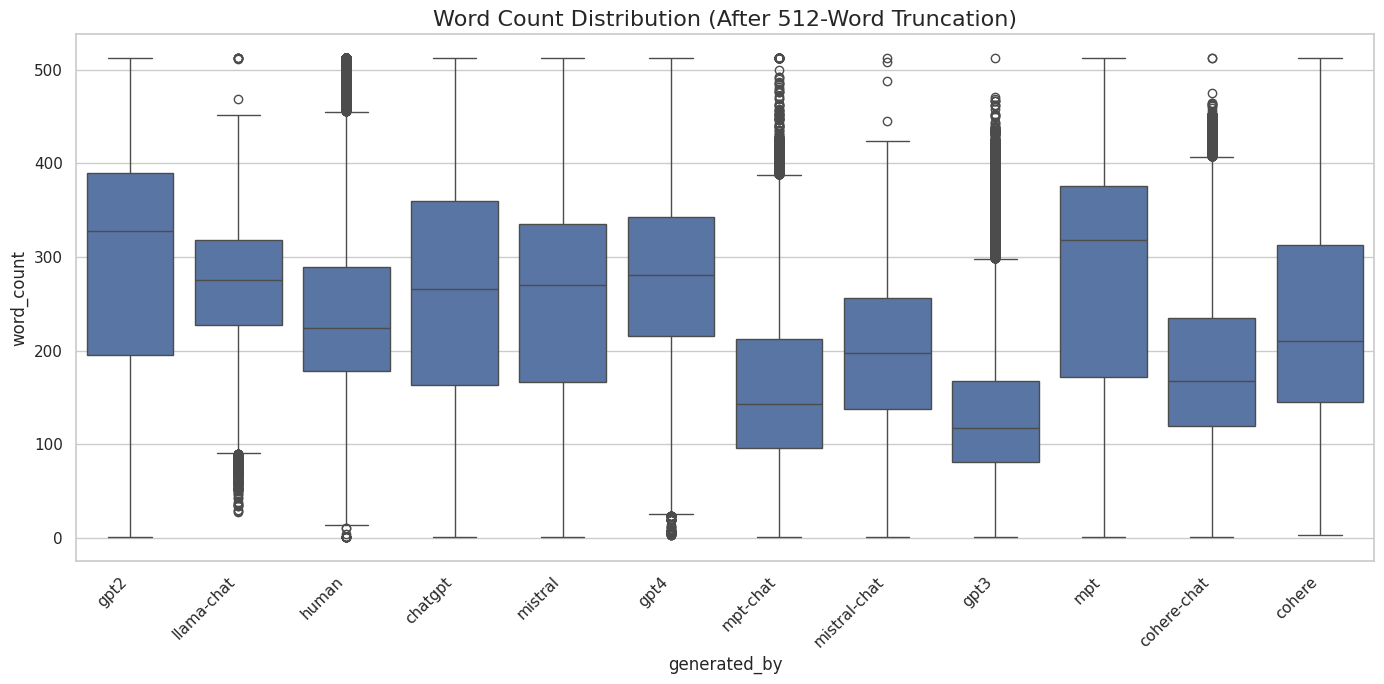

Cleaned Word Count Percentiles:
75%    319.0
90%    382.0
95%    407.0
99%    463.0
max    512.0
Name: word_count, dtype: float64


In [8]:
# --- Plot 1: Cleaned Word Count Line Plot (KDE) ---
plt.figure(figsize=(14, 7))
ax_clean_word = sns.kdeplot(data=cleaned_df, x='word_count', hue='generated_by', 
                            common_norm=False, linewidth=2)
plt.title('Word Count Distribution (Truncated at 512 Words)', fontsize=16)

sns.move_legend(ax_clean_word, "upper left", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.savefig(f'./images/Word Count Distribution (Truncated at 512 Words) Line.png', dpi=300, bbox_inches='tight', transparent=False)
plt.show()


# --- Plot 2: Cleaned Character Count Boxplot ---
plt.figure(figsize=(14, 7))
# We can enable fliers (outliers) again since the massive extremes are gone
ax_clean_char = sns.boxplot(data=cleaned_df, x='generated_by', y='word_count')
plt.title('Word Count Distribution (After 512-Word Truncation)', fontsize=16)

plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'./images/Word Count Distribution (After 512-Word Truncation) Line.png', dpi=300, bbox_inches='tight', transparent=False)
plt.show()

# --- Percentile Stats for Cleaned Data ---
percentiles = [0.75, 0.90, 0.95, 0.99]
print("Cleaned Word Count Percentiles:")
print(cleaned_df['word_count'].describe(percentiles=percentiles)[['75%', '90%', '95%', '99%', 'max']])

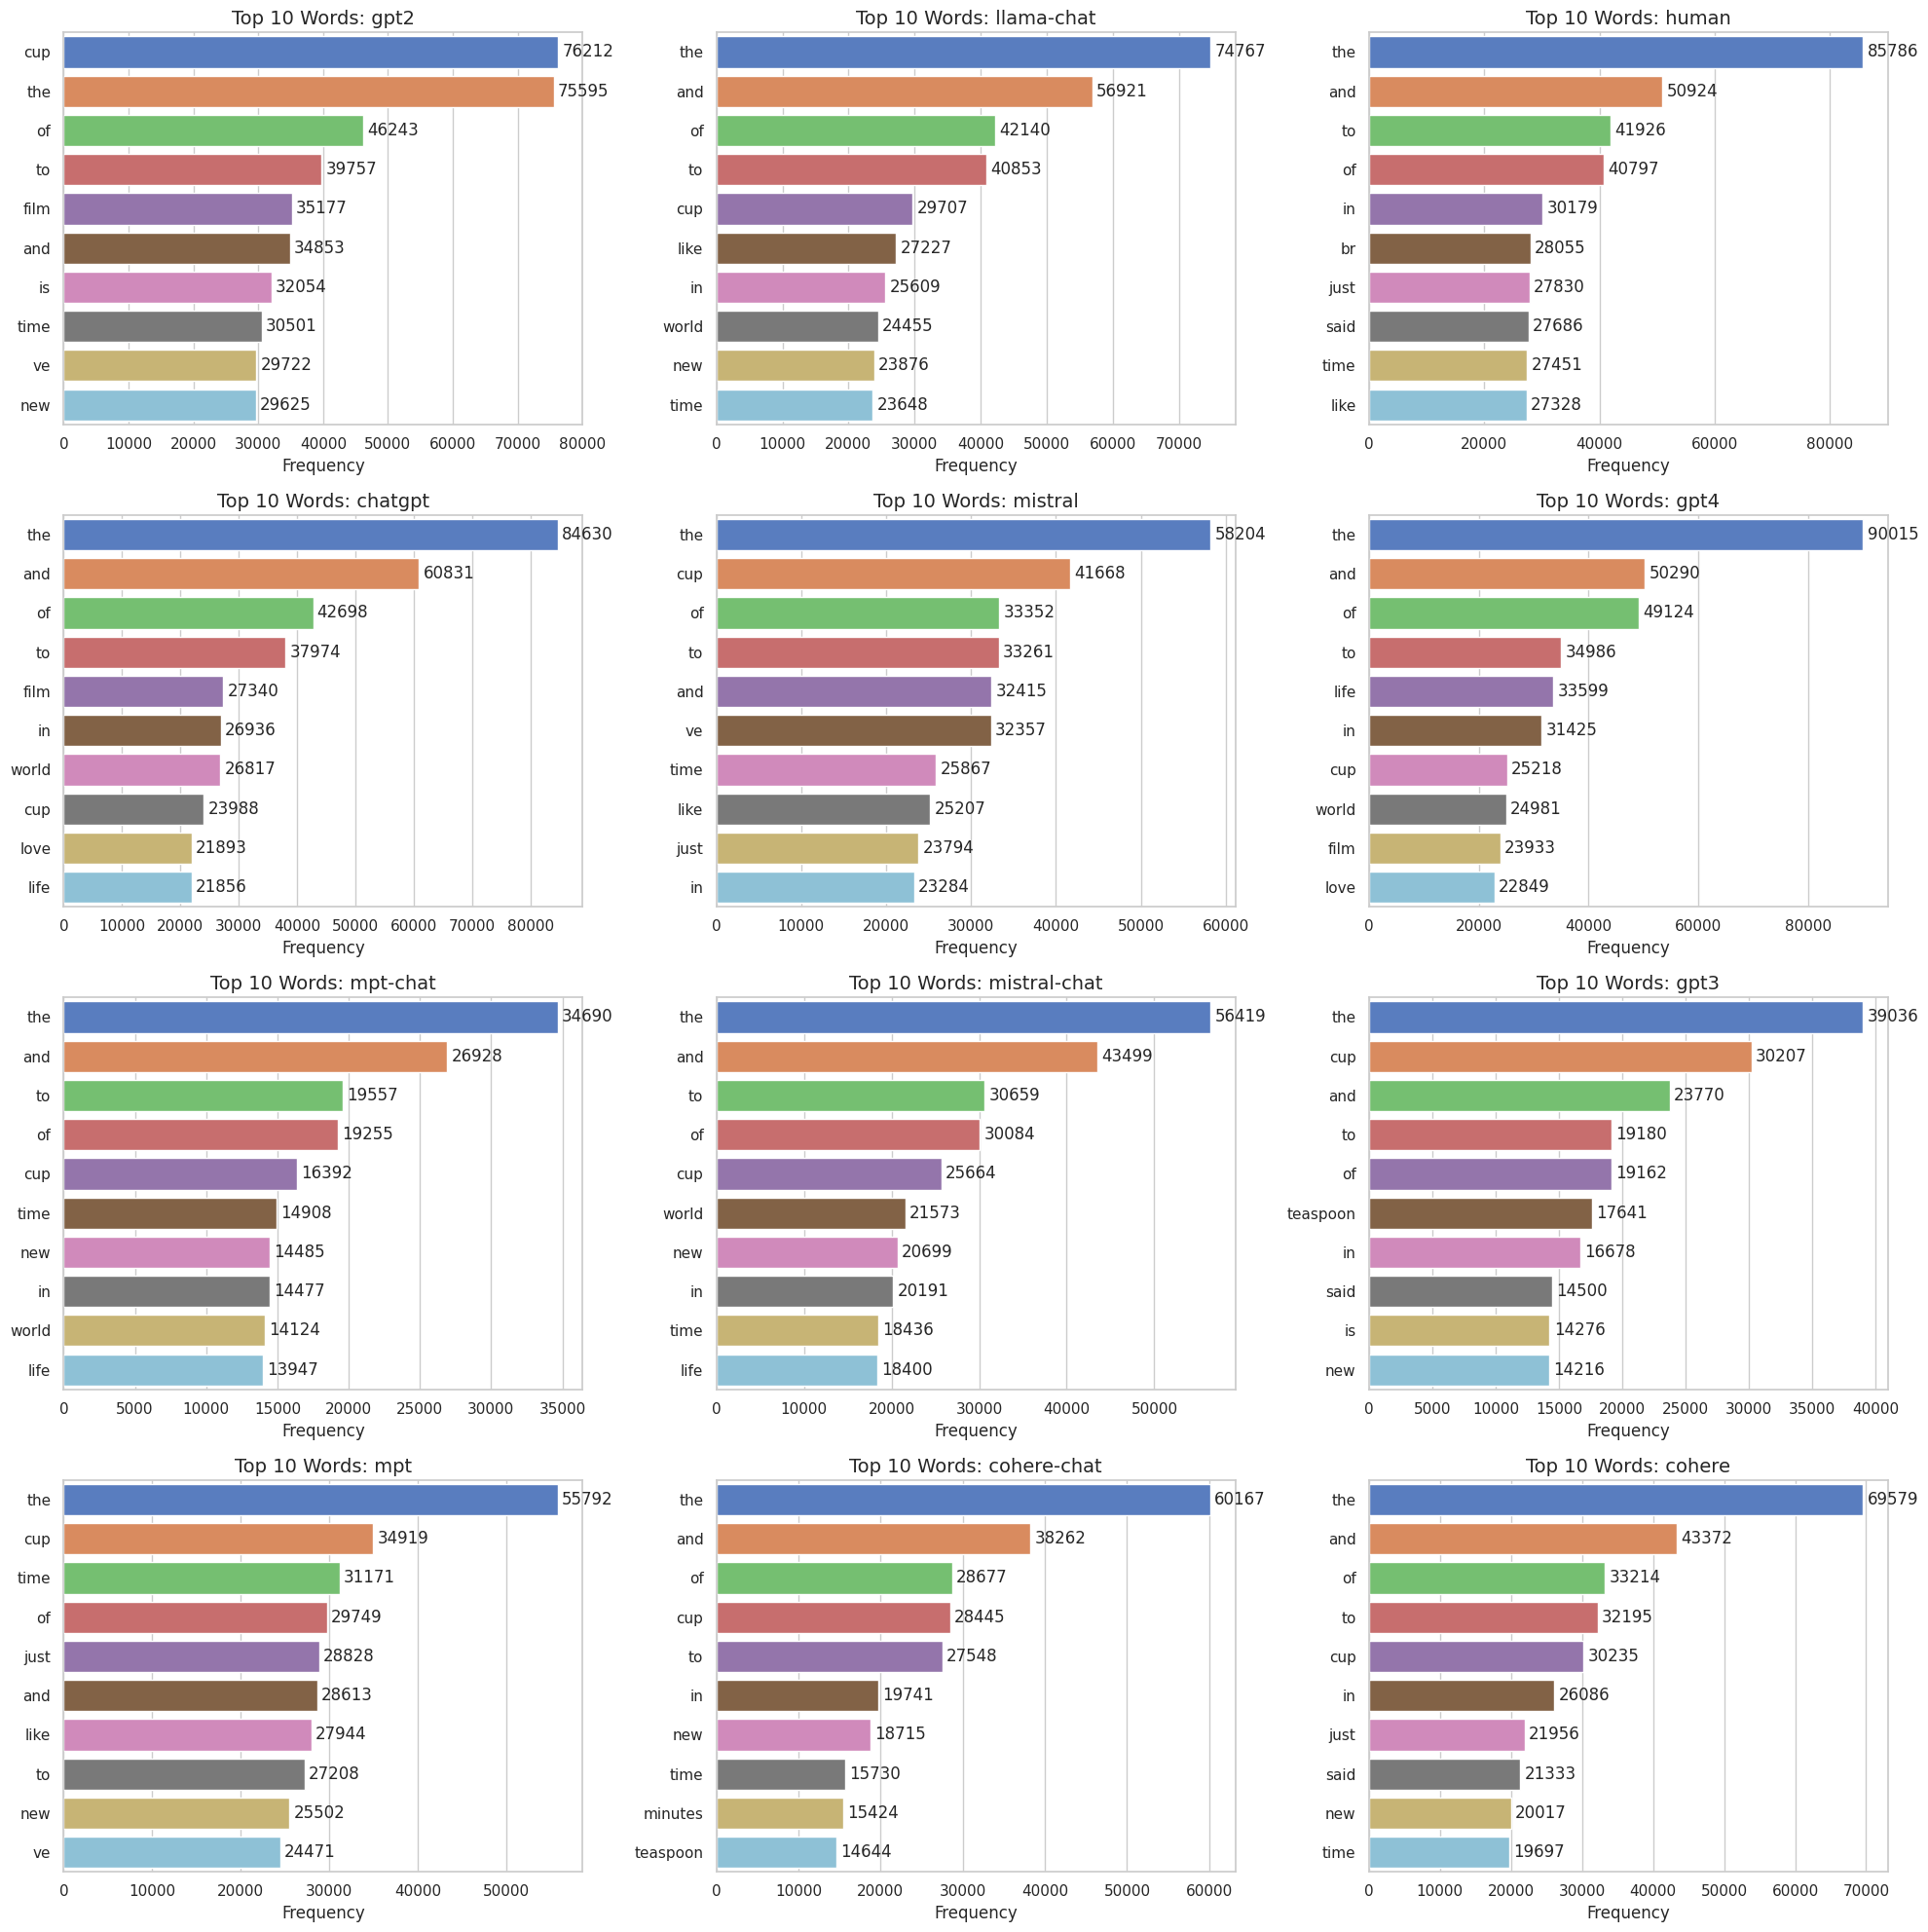

In [9]:
categories = train_df['generated_by'].unique()

# Setup the grid: 4 columns, and calculate needed rows based on category count
ncols = 3
nrows = math.ceil(len(categories) / ncols)

# Create the subplots
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(20, 5 * nrows))
axes = axes.flatten() # Flatten to iterate easily

# Fast Vectorizer to extract word counts and remove stop words
vec = CountVectorizer(stop_words='english', max_features=2000)

for i, cat in enumerate(categories):
    ax = axes[i]
    
    # Isolate text for this specific category
    cat_text = train_df[train_df['generated_by'] == cat]['text'].fillna('')
    
    if len(cat_text) > 0:
        # Calculate frequencies
        matrix = vec.fit_transform(cat_text)
        word_freq = zip(vec.get_feature_names_out(), matrix.sum(axis=0).tolist()[0])
        
        # Sort by highest frequency first and slice top 10
        sorted_words = sorted(word_freq, key=lambda x: x[1], reverse=True)[:10]
        
        # Unzip into separate lists for plotting
        words, counts = zip(*sorted_words)
        
        # Plot horizontal bars
        sns.barplot(x=list(counts), y=list(words), ax=ax, palette='muted') # pastel, muted, bright
        ax.set_title(f'Top 10 Words: {cat}', fontsize=14)
        ax.set_xlabel('Frequency')
        ax.set_ylabel('')
        
        # Add the exact count numbers to the end of the bars for readability
        for container in ax.containers:
            ax.bar_label(container, padding=3)

# Hide any extra empty subplots if the number of categories isn't a perfect multiple of 4
for j in range(len(categories), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.savefig(f'./images/Word Frequency Per Model.png', dpi=300, bbox_inches='tight', transparent=False)
plt.show()